# Лабораторная работа №4
## Аналитика как конкурентное преимущество

**Задание 1.** Комплексная система мультиплеерной аналитики «Multiplayer Balance & Matchmaking Insights»: качество матчмейкинга, баланс карт, антифрод.
**Задание 2.** Интерактивный экран «Матрица соревновательного баланса персонажей» (Pick Rate vs Win Rate).

Данные — синтетические логи соревновательного шутера 5v5, сгенерированные скриптом `src/generate_data.py` с заложенными «скрытыми аномалиями» для проверки алгоритмов.

## Задание 1. Шаг 1. Проектирование хранилища и загрузка данных

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
REPORTS = '../reports'

In [2]:
# Схема данных: ID — строки, MMR — целые, метрики эффективности — дробные
matches_df = pd.read_csv('../data/matches.csv', parse_dates=['match_date'], keep_default_na=False,
                         dtype={'match_id': 'string', 'map_id': 'string', 'server_region': 'string',
                                'winning_team': 'string', 'duration_sec': 'int64', 'queue_time_sec': 'float64'})
players_df = pd.read_csv('../data/player_stats.csv',
                         dtype={'match_id': 'string', 'player_id': 'string', 'team_side': 'string',
                                'hero_id': 'string', 'weapon_id': 'string', 'kills': 'int64', 'deaths': 'int64',
                                'assists': 'int64', 'mmr_before': 'int64', 'mmr_after': 'int64', 'ping': 'int64'})
reports_df = pd.read_csv('../data/reports.csv', dtype='string')

for name, df in [('matches_df', matches_df), ('players_df', players_df), ('reports_df', reports_df)]:
    print(f"{name}: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
print()
players_df.info()

matches_df: 3,000 строк × 7 столбцов
players_df: 30,000 строк × 11 столбцов
reports_df: 2,319 строк × 4 столбцов

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   match_id    30000 non-null  string
 1   player_id   30000 non-null  string
 2   team_side   30000 non-null  string
 3   hero_id     30000 non-null  string
 4   weapon_id   30000 non-null  string
 5   kills       30000 non-null  int64 
 6   deaths      30000 non-null  int64 
 7   assists     30000 non-null  int64 
 8   mmr_before  30000 non-null  int64 
 9   mmr_after   30000 non-null  int64 
 10  ping        30000 non-null  int64 
dtypes: int64(6), string(5)
memory usage: 2.5 MB


In [3]:
display(matches_df.head(3))
display(players_df.head(3))
display(reports_df.head(3))

# Проверки целостности реляционной структуры
assert matches_df['match_id'].is_unique
assert players_df.groupby('match_id').size().eq(10).all(), 'в каждом матче должно быть 10 игроков'
assert players_df.groupby(['match_id', 'team_side']).size().eq(5).all(), 'команды 5 на 5'
assert players_df['match_id'].isin(matches_df['match_id']).all()
assert reports_df['match_id'].isin(matches_df['match_id']).all()
print("Целостность: 10 игроков на матч, команды 5v5, все ссылки match_id корректны")
print(f"Уникальных игроков: {players_df['player_id'].nunique():,}; "
      f"период: {matches_df['match_date'].min().date()} — {matches_df['match_date'].max().date()}")
print("Жалобы по причинам:", reports_df['reason'].value_counts().to_dict())

,match_id,map_id,duration_sec,server_region,winning_team,queue_time_sec,match_date
0,MATCH_00000,De_Dust2,1375,EU,Defense,112.5,2026-09-06 11:37:00
1,MATCH_00001,De_Inferno,1702,EU,Attack,132.2,2026-09-12 00:49:00
2,MATCH_00002,De_Mirage,1671,ASIA,Defense,75.2,2026-09-06 17:00:00


,match_id,player_id,team_side,hero_id,weapon_id,kills,deaths,assists,mmr_before,mmr_after,ping
0,MATCH_00000,PLAYER_00599,Attack,Hero_9,SMG_MP9,23,16,11,2546,2518,77
1,MATCH_00000,PLAYER_00525,Attack,Hero_8,SMG_MP9,13,19,5,2334,2308,29
2,MATCH_00000,PLAYER_01570,Attack,Hero_20,Shotgun_Nova,7,21,4,2096,2070,72


,match_id,reporter_id,reported_id,reason
0,MATCH_00000,PLAYER_01923,PLAYER_00074,cheating
1,MATCH_00000,PLAYER_00529,PLAYER_00074,cheating
2,MATCH_00000,PLAYER_01384,PLAYER_00599,toxicity


Целостность: 10 игроков на матч, команды 5v5, все ссылки match_id корректны
Уникальных игроков: 1,953; период: 2026-09-01 — 2026-09-14
Жалобы по причинам: {'cheating': 1294, 'toxicity': 859, 'afk': 166}


## Шаг 2. Модуль А: качество матчмейкинга
* **ΔMMR** = |Mean(MMR_Attack) − Mean(MMR_Defense)| — разница средней силы команд;
* **StDev(MMR)** внутри команды — признак «паровоза» (новичок с хардкорщиками);
* **Unfair_Match** — флаг матчей с ΔMMR > 250.

In [4]:
team_mmr = (players_df.groupby(['match_id', 'team_side'])['mmr_before']
            .agg(['mean', 'std']).unstack())
team_mmr.columns = [f'{stat}_{side}' for stat, side in team_mmr.columns]
team_mmr = team_mmr.rename(columns={'mean_Attack': 'mmr_attack', 'mean_Defense': 'mmr_defense',
                                    'std_Attack': 'std_attack', 'std_Defense': 'std_defense'}).reset_index()
team_mmr['mmr_delta'] = (team_mmr['mmr_attack'] - team_mmr['mmr_defense']).abs()
team_mmr['max_team_std'] = team_mmr[['std_attack', 'std_defense']].max(axis=1)
team_mmr['Unfair_Match'] = team_mmr['mmr_delta'] > 250

mmr_analysis = team_mmr.merge(matches_df, on='match_id')
mmr_analysis['stronger_side'] = np.where(mmr_analysis['mmr_attack'] >= mmr_analysis['mmr_defense'], 'Attack', 'Defense')
mmr_analysis['stronger_won'] = mmr_analysis['stronger_side'] == mmr_analysis['winning_team']

print(f"Средний дисбаланс (ΔMMR): {mmr_analysis['mmr_delta'].mean():.1f} пунктов, медиана {mmr_analysis['mmr_delta'].median():.1f}")
print(f"Матчей с критическим дисбалансом (ΔMMR > 250): {mmr_analysis['Unfair_Match'].sum()} "
      f"({mmr_analysis['Unfair_Match'].mean() * 100:.1f}%)")
print("\nПерцентили ΔMMR:")
print(mmr_analysis['mmr_delta'].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(1).to_string())

Средний дисбаланс (ΔMMR): 91.6 пунктов, медиана 31.6
Матчей с критическим дисбалансом (ΔMMR > 250): 491 (16.4%)

Перцентили ΔMMR:
0.25     14.4
0.50     31.6
0.75     74.6
0.90    324.0
0.95    397.0
0.99    505.5


### Win Rate более сильной команды по коридорам ΔMMR

,matches,stronger_win_rate,avg_duration_min
delta_bin,,,
0–50,1982,51.7,30.8
50–100,373,59.8,29.7
100–150,35,65.7,30.6
150–250,119,74.8,29.2
250–400,349,81.1,28.7
400+,142,85.2,27.5


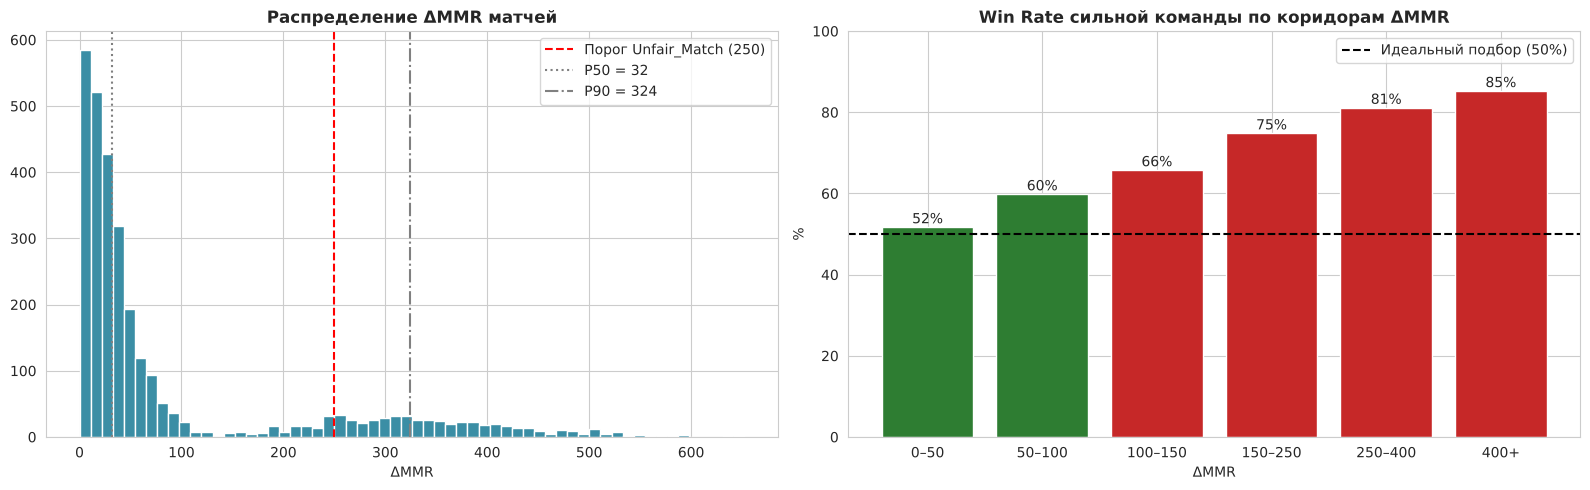

In [5]:
bins = [0, 50, 100, 150, 250, 400, np.inf]
labels = ['0–50', '50–100', '100–150', '150–250', '250–400', '400+']
mmr_analysis['delta_bin'] = pd.cut(mmr_analysis['mmr_delta'], bins=bins, labels=labels, include_lowest=True)
corridor = mmr_analysis.groupby('delta_bin', observed=True).agg(
    matches=('match_id', 'count'), stronger_win_rate=('stronger_won', 'mean'),
    avg_duration_min=('duration_sec', lambda x: x.mean() / 60))
corridor['stronger_win_rate'] *= 100
display(corridor.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(mmr_analysis['mmr_delta'], bins=60, color='#3B8EA5', edgecolor='white')
axes[0].axvline(250, color='red', linestyle='--', label='Порог Unfair_Match (250)')
for q, ls in [(0.5, ':'), (0.9, '-.')]:
    v = mmr_analysis['mmr_delta'].quantile(q)
    axes[0].axvline(v, color='gray', linestyle=ls, label=f'P{int(q * 100)} = {v:.0f}')
axes[0].set_title('Распределение ΔMMR матчей', fontweight='bold'); axes[0].set_xlabel('ΔMMR'); axes[0].legend()
axes[1].bar(corridor.index.astype(str), corridor['stronger_win_rate'],
            color=['#2E7D32' if v < 60 else '#C62828' for v in corridor['stronger_win_rate']])
axes[1].axhline(50, color='black', linestyle='--', label='Идеальный подбор (50%)')
for i, v in enumerate(corridor['stronger_win_rate']):
    axes[1].text(i, v + 1, f'{v:.0f}%', ha='center')
axes[1].set_ylim(0, 100); axes[1].set_title('Win Rate сильной команды по коридорам ΔMMR', fontweight='bold')
axes[1].set_xlabel('ΔMMR'); axes[1].set_ylabel('%'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{REPORTS}/matchmaking_quality.png', dpi=150); plt.show()

### Время поиска vs качество подбора и «паровозы»

,queue_sec,mmr_delta,unfair_share,team_std
queue_bin,,,,
"(14.999, 30.2]",24.60,127.61,0.23,275.03
"(30.2, 39.68]",35.40,112.19,0.21,259.88
"(39.68, 47.7]",43.40,117.45,0.22,249.73
"(47.7, 56.66]",52.60,104.44,0.20,238.87
"(56.66, 65.7]",61.00,90.57,0.17,236.57
"(65.7, 76.3]",71.00,84.63,0.16,222.72
"(76.3, 91.8]",84.05,71.39,0.12,215.37
"(91.8, 112.0]",100.15,81.11,0.15,189.50
"(112.0, 144.72]",125.50,73.78,0.12,175.48


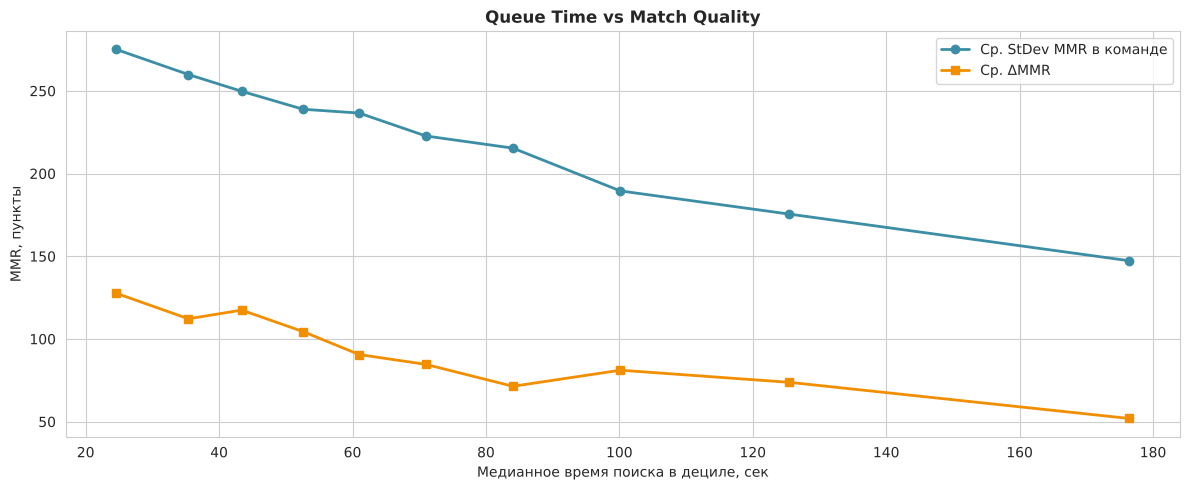

Порог «паровоза»: StDev MMR в команде > P95 = 344; таких матчей 150
Корреляция времени поиска с StDev команды: -0.51, с ΔMMR: -0.15


In [6]:
mmr_analysis['queue_bin'] = pd.qcut(mmr_analysis['queue_time_sec'], 10)
queue = mmr_analysis.groupby('queue_bin', observed=True).agg(
    queue_sec=('queue_time_sec', 'median'), mmr_delta=('mmr_delta', 'mean'),
    unfair_share=('Unfair_Match', 'mean'), team_std=('max_team_std', 'mean'))
display(queue.round(2))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(queue['queue_sec'], queue['team_std'], marker='o', color='#3B8EA5', linewidth=2, label='Ср. StDev MMR в команде')
ax1.plot(queue['queue_sec'], queue['mmr_delta'], marker='s', color='#F18F01', linewidth=2, label='Ср. ΔMMR')
ax1.set_xlabel('Медианное время поиска в дециле, сек'); ax1.set_ylabel('MMR, пункты')
ax1.set_title('Queue Time vs Match Quality', fontweight='bold'); ax1.legend()
plt.tight_layout(); plt.savefig(f'{REPORTS}/queue_vs_quality.png', dpi=150); plt.show()

hi_std = mmr_analysis['max_team_std'].quantile(0.95)
print(f"Порог «паровоза»: StDev MMR в команде > P95 = {hi_std:.0f}; таких матчей {(mmr_analysis['max_team_std'] > hi_std).sum()}")
print(f"Корреляция времени поиска с StDev команды: {mmr_analysis[['queue_time_sec', 'max_team_std']].corr().iloc[0, 1]:.2f}, "
      f"с ΔMMR: {mmr_analysis[['queue_time_sec', 'mmr_delta']].corr().iloc[0, 1]:.2f}")